In [134]:
#!pip install xgboost

In [135]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import  mean_absolute_error
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from mlxtend.plotting import scatterplotmatrix
from sklearn.impute import KNNImputer
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import xgboost as xgb
from sklearn.model_selection import RepeatedKFold, cross_val_score

In [136]:
# Carga el dataframe desde un archivo Excel
df = pd.read_excel('entrenamiento.xlsx')
df.head(12)

,C1,C2,C3,C4,C5,C6,C7,C7.1,C9,C10,C11,des
0,6.8,0.190620,0.307485,18.10,46.00,32.0,4.897840,1.00000,3.27,0.392042,8.8,5
1,6.2,0.246860,NaN,5.00,43.00,50.0,5.241747,0.99318,3.23,0.494696,10.8,6
2,6.7,0.350657,0.329304,12.10,0.04,61.0,5.517453,0.99794,3.31,0.457425,9.7,5
3,6.8,0.254642,0.405465,13.30,53.00,48.0,5.273000,0.99740,3.09,0.371564,9.4,5
4,6.6,0.215111,0.239017,15.80,35.00,46.0,5.241747,0.99820,3.24,0.412110,9.2,5
5,6.7,0.329304,0.215111,2.70,17.00,22.0,4.394449,0.99084,3.03,0.314811,11.5,5
6,9.2,0.536493,0.207014,6.20,42.00,15.0,4.543295,0.99480,NaN,0.292670,10.1,6
7,6.4,4.836282,0.254642,5.85,42.00,24.0,4.605170,992.00000,3.23,0.277632,NaN,7
8,6.4,0.292670,0.364643,8.20,43.00,54.0,5.308268,0.99551,3.18,0.392042,9.5,5
9,6.2,0.148420,0.277632,1.10,36.00,74.0,5.220356,0.99096,3.22,0.343590,11.0,6


In [137]:
# Realiza análisis de los valores faltantes
df.isna().sum()

C1      234
C2      254
C3      270
C4      282
C5      259
C6      263
C7      273
C7.1    272
C9      260
C10     279
C11     260
des       0
dtype: int64

In [138]:
# Limpiamos los datos: reemplazando los valores NaN con la media de la columna
#imputer = SimpleImputer(strategy='mean')
imputer = KNNImputer( n_neighbors=7)
df= pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

In [139]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
C1,3918.0,6.853728,0.825612,3.800000,6.314286,6.800000,7.300000,14.200000
C2,3918.0,0.422772,0.961309,0.076961,0.198851,0.239017,0.285179,6.913737
C3,3918.0,0.283826,0.084306,0.000000,0.239017,0.277632,0.322083,0.802002
C4,3918.0,6.394170,4.957570,0.600000,1.800000,5.300000,9.700000,65.800000
C5,3918.0,40.590233,24.402618,0.020000,33.000000,41.000000,48.000000,346.000000
C6,3918.0,35.364326,16.793030,2.000000,24.000000,34.000000,45.964286,289.000000
C7,3918.0,4.886453,0.333680,2.302585,4.700480,4.905275,5.123964,6.089045
C7.1,3918.0,67.877344,238.303563,0.987110,0.991850,0.994300,0.997332,1001.000000
C9,3918.0,3.188172,0.148311,2.720000,3.090000,3.180000,3.280000,3.820000
C10,3918.0,0.395422,0.072290,0.198851,0.343590,0.391549,0.431782,0.732368


<AxesSubplot: >

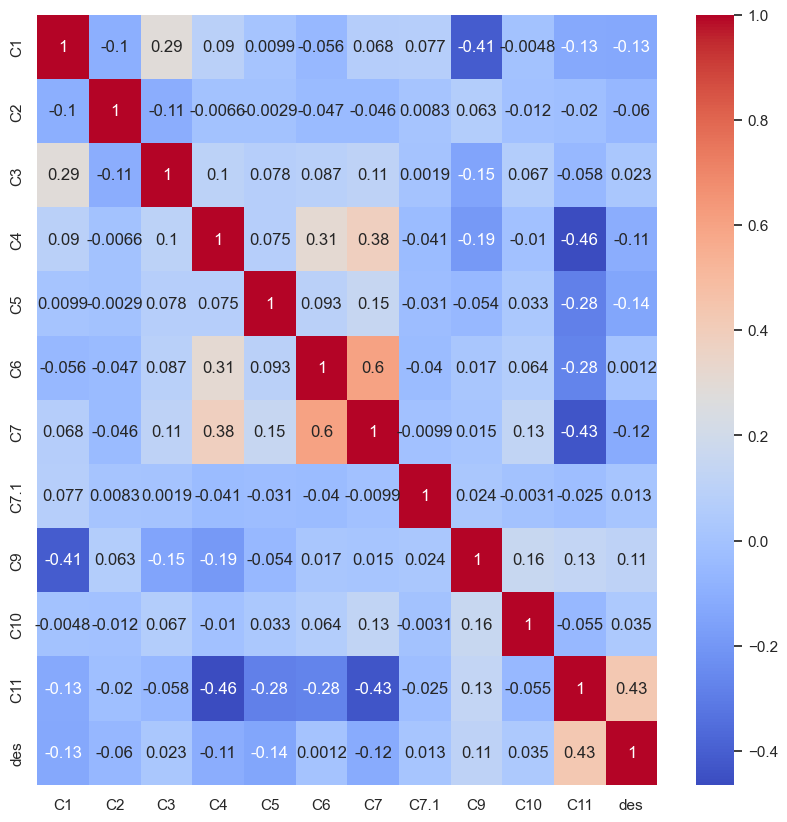

In [140]:
plt.figure(figsize=(10,10))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')

In [141]:
df.corr().des.sort_values(ascending=False)[1:]

C11     0.430887
C9      0.113092
C10     0.034669
C3      0.023007
C7.1    0.013490
C6      0.001175
C2     -0.059733
C4     -0.105653
C7     -0.118579
C1     -0.129720
C5     -0.142719
Name: des, dtype: float64

In [142]:
columnas = ['C9','C10','C11', 'des']

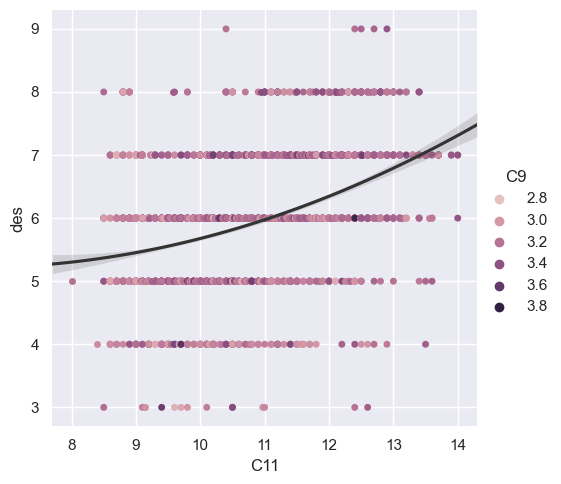

In [143]:
sns.set_theme(palette='deep')
g= sns.catplot(
    data=df[columnas],
    x="C11", y="des", hue="C9",
    native_scale=True, zorder=1
)
sns.regplot(
    data=df[columnas],
    x="C11", y="des",scatter=False, #hue= 'C9',
    truncate= False, order=2, color= '.2' #palette=cmap, sizes=(10, 200),
)
#g.set(xscale="log", yscale="log")
#g.ax.xaxis.grid(True, "minor", linewidth=.25)
#g.ax.yaxis.grid(True, "minor", linewidth=.25)
g.despine(left=True, bottom=True)

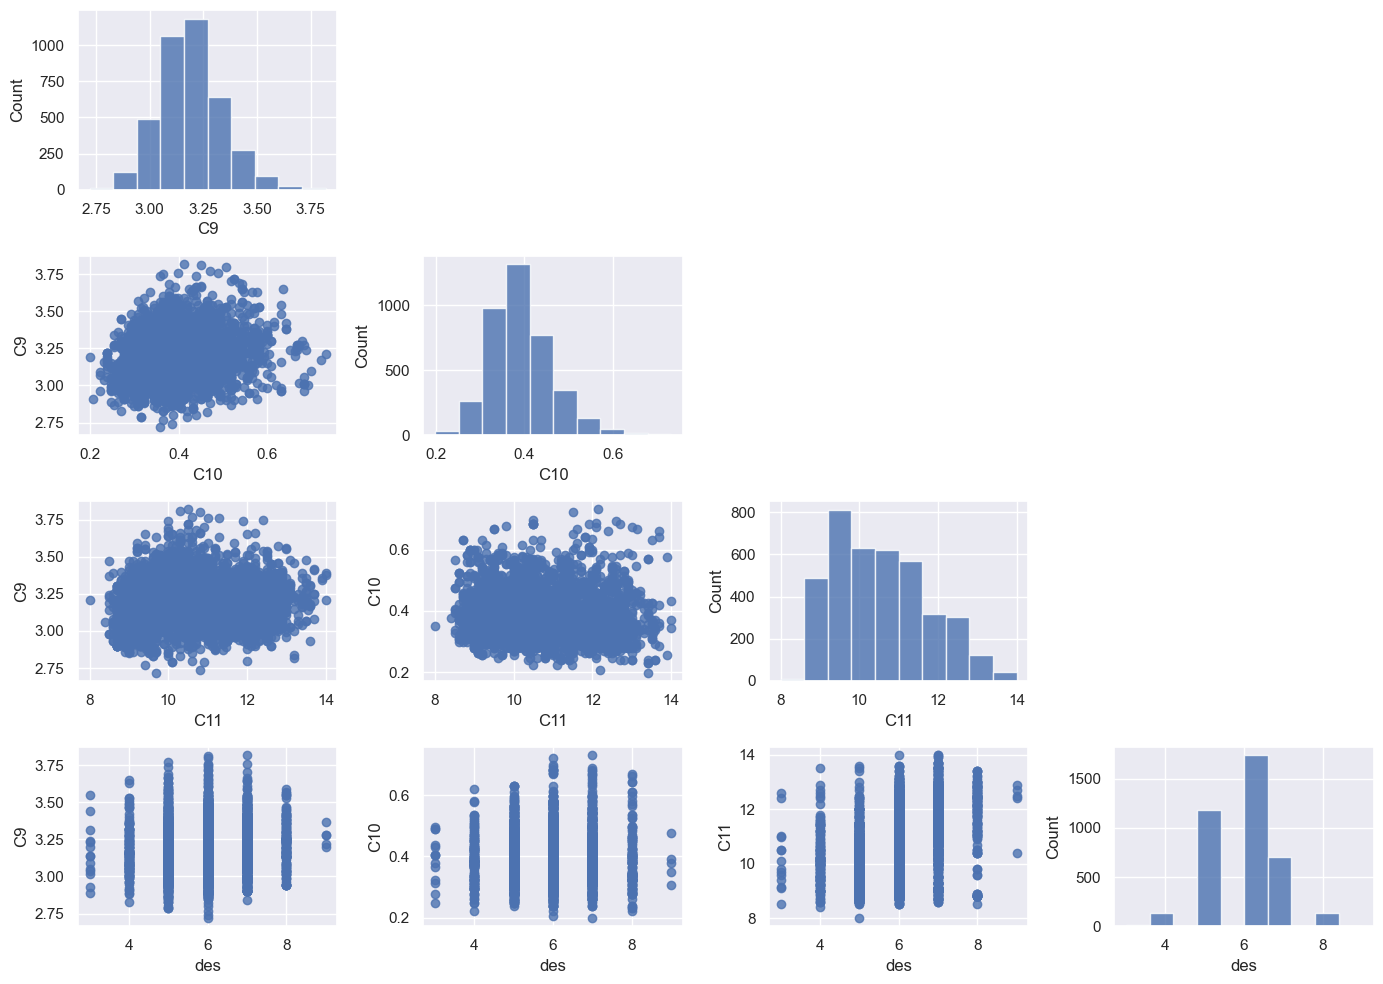

In [144]:
scatterplotmatrix(df[columnas].values, figsize= (14,10),names=columnas, alpha=0.8)
plt.tight_layout()
plt.show()

In [145]:
# Separamos las características (X) y la variable objetivo (y)
X = df.drop("des", axis = 1)
y = df["des"]


In [146]:

# Escala los datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

División en entrenamiento y test:

In [147]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled,y,
                                                    test_size = 0.25,
                                                    random_state = 123)

##XGBoost

Definición del modelo:

In [148]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)


In [153]:
# Defino los parámetros del modelo XGBoost para regresión
hiperp= {
    'objective': 'reg:squarederror',
    'eval_metric': 'mae',
    'max_depth': 3,
    'learning_rate': 0.1,
    'n_estimators': 100
    }

In [154]:
# Entrenamos el modelo
modelo = xgb.train(hiperp, dtrain, num_boost_round=100)

[16:40:34] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0fdc6d574b9c0d168-1\xgboost\xgboost-ci-windows\src\learner.cc:767: 
Parameters: { "n_estimators" } are not used.



In [155]:
# Realizar predicciones en el conjunto de prueba
predictions = modelo.predict(dtest)

La métrica seleccionada es mean_absolute_error:

In [156]:

#print(f"MAE {score_abs.mean()}, std: {scores.std()}")
mae = mean_absolute_error(y_test, predictions)
print(f'MAE: {mae}')

MAE: 0.00014988305617351922


In [157]:
# Crear un DataFrame con las predicciones
pred_df = pd.DataFrame({'Prediccion_modelo_Ernesto': predictions})

# Exportar el DataFrame con las predicciones a un archivo Excel
pred_df.to_excel('prediccion_modelo118_ernesto.xlsx', index=False)